In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, json, unicodedata
import numpy as np, pandas as pd, torch

BASE = "/content/drive/MyDrive/JIS - capacitismo/data_externa"
OUT  = "/content/drive/MyDrive/JIS - capacitismo/results"
os.makedirs(OUT, exist_ok=True)
SEED = 42

def norm(s):
    s = str(s).lower()
    s = re.sub(r'https?://\S+|www\.\S+', ' ', s)
    s = re.sub(r'@\w+', ' ', s)
    s = re.sub(r'^rt\b', ' ', s)
    s = re.sub(r'\buser\b', ' ', s)
    s = unicodedata.normalize('NFKC', s)
    s = re.sub(r'[^\w\s]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

hate = pd.read_csv(f"{BASE}/hatebr.csv").rename(columns={"comentario": "text", "label_final": "label"})[["id", "text", "label"]]
hate["text"] = hate.text.astype(str)
told = pd.read_csv(f"{BASE}/told_br/1annotator/ptbr_test_1annotator.csv").rename(columns={"toxic": "label"})

ht = pd.read_parquet(f"{BASE}/harmful_text_pt_train.parquet")
olid = pd.concat([pd.read_parquet(f"{BASE}/olid_br_train.parquet"), pd.read_parquet(f"{BASE}/olid_br_test.parquet")])
seen = set(ht.harmless.map(norm)) | set(ht.harmful.map(norm)) | set(olid.text.map(norm))
told["unseen"] = ~told.text.map(norm).isin(seen)

print("HateBR:", len(hate), "| ToLD-Br teste:", len(told), "| não vistos:", int(told.unseen.sum()))

Mounted at /content/drive
HateBR: 7000 | ToLD-Br teste: 2100 | não vistos: 2010


In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", device)

@torch.no_grad()
def score_corpora(model_name, kind, corpora, batch_size=32, max_length=512):
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device).eval()
    if kind == "bertimbau":
        off_id = {v: k for k, v in model.config.id2label.items()}["OFFENSIVE"]
    results = []
    for texts in corpora:
        scores = []
        for i in range(0, len(texts), batch_size):
            enc = tok(texts[i:i + batch_size], padding=True, truncation=True,
                      max_length=max_length, return_tensors="pt").to(device)
            logits = model(**enc).logits
            if kind == "bertimbau":
                s = torch.softmax(logits, dim=-1)[:, off_id]
            else:
                s = 1 - torch.sigmoid(logits.squeeze(-1))
            scores.extend(s.float().cpu().tolist())
        results.append(np.array(scores))
    del model
    torch.cuda.empty_cache()
    return results

MODELS = {"tox1": ("dougtrajano/toxic-comment-classification", "bertimbau"),
          "tox2": ("nicholasKluge/ToxiGuardrailPT", "guardrail")}

for key, (name, kind) in MODELS.items():
    hate[f"{key}_score"], told[f"{key}_score"] = score_corpora(name, kind, [hate.text.tolist(), told.text.tolist()])

hate.to_csv(f"{OUT}/hatebr_scores.csv", index=False)
told.to_csv(f"{OUT}/told_br_test_scores.csv", index=False)

acc = ((told.tox2_score >= 0.5).astype(int) == told.label).mean()
print(f"Conferência: acurácia do ToxiGuardrail-PT no teste do ToLD-Br com 0,5 = {acc:.4f} (a ficha do modelo diz 0,7404)")

dispositivo: cuda


config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/678k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Conferência: acurácia do ToxiGuardrail-PT no teste do ToLD-Br com 0,5 = 0.7405 (a ficha do modelo diz 0,7404)


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score, accuracy_score, f1_score

def youden_threshold(y, s):
    fpr, tpr, thr = roc_curve(y, s)
    return float(thr[np.argmax(tpr - fpr)])

def fpr5_threshold(y, s, target=0.05):
    return float(np.quantile(s[y == 0], 1 - target))

def evaluate(y, s, thr):
    pred = (s >= thr).astype(int)
    return {"acuracia": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, average="macro"),
            "f1_ofensivo": f1_score(y, pred), "taxa_falso_positivo": float(pred[y == 0].mean()),
            "sensibilidade": float(pred[y == 1].mean())}

half_a, half_b = train_test_split(hate, test_size=0.5, stratify=hate.label, random_state=SEED)
told_unseen = told[told.unseen].reset_index(drop=True)

thresholds, rows = {}, []
for key in ["tox1", "tox2"]:
    ya, sa = half_a.label.values, half_a[f"{key}_score"].values
    thresholds[key] = {"padrao_0.5": 0.5, "youden": youden_threshold(ya, sa), "fpr_5": fpr5_threshold(ya, sa)}
    for corpus, d in [("HateBR metade B", half_b), ("ToLD-Br teste nao visto", told_unseen)]:
        y, s = d.label.values, d[f"{key}_score"].values
        for name, thr in thresholds[key].items():
            rows.append({"modelo": key, "corpus": corpus, "limiar": name, "valor_limiar": thr,
                         "auc_roc": roc_auc_score(y, s), "precisao_media": average_precision_score(y, s),
                         **evaluate(y, s, thr)})

metrics = pd.DataFrame(rows)
metrics.to_csv(f"{OUT}/calibration_metrics.csv", index=False)
with open(f"{OUT}/thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)

print(metrics.round(3).to_string())
print(json.dumps(thresholds, indent=2))

   modelo                   corpus      limiar  valor_limiar  auc_roc  precisao_media  acuracia  f1_macro  f1_ofensivo  taxa_falso_positivo  sensibilidade
0    tox1          HateBR metade B  padrao_0.5         0.500    0.932           0.942     0.827     0.825        0.842                0.272          0.925
1    tox1          HateBR metade B      youden         0.797    0.932           0.942     0.853     0.852        0.843                0.084          0.789
2    tox1          HateBR metade B       fpr_5         0.841    0.932           0.942     0.841     0.840        0.823                0.055          0.738
3    tox1  ToLD-Br teste nao visto  padrao_0.5         0.500    0.807           0.781     0.731     0.721        0.668                0.155          0.595
4    tox1  ToLD-Br teste nao visto      youden         0.797    0.807           0.781     0.673     0.620        0.478                0.038          0.329
5    tox1  ToLD-Br teste nao visto       fpr_5         0.841    0.807 

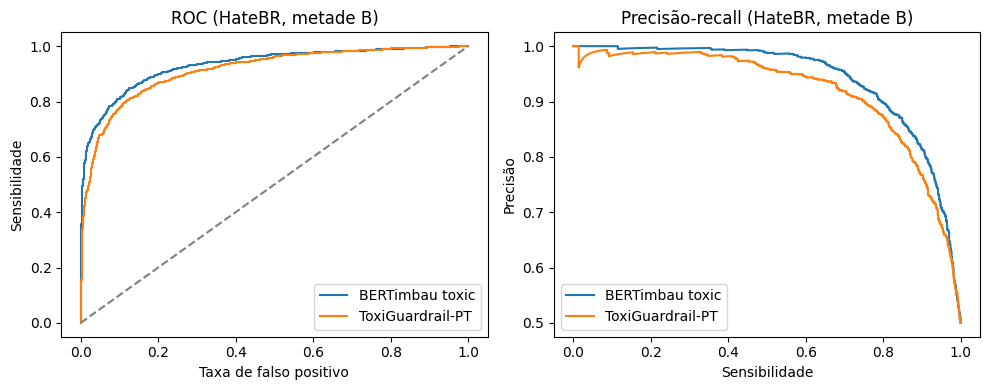

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

names = {"tox1": "BERTimbau toxic", "tox2": "ToxiGuardrail-PT"}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for key in ["tox1", "tox2"]:
    y, s = half_b.label.values, half_b[f"{key}_score"].values
    fpr, tpr, _ = roc_curve(y, s)
    prec, rec, _ = precision_recall_curve(y, s)
    ax[0].plot(fpr, tpr, label=names[key])
    ax[1].plot(rec, prec, label=names[key])
ax[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
ax[0].set(xlabel="Taxa de falso positivo", ylabel="Sensibilidade", title="ROC (HateBR, metade B)")
ax[1].set(xlabel="Sensibilidade", ylabel="Precisão", title="Precisão-recall (HateBR, metade B)")
ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT}/calibration_curves.png", dpi=200)
plt.show()

## C4. Sensibilidade das métricas de decisão ao limiar (v1.1)

Versões do corpus:
- **v1**: corpus do artigo do WICS (3.105 pares, com sentenças repetidas). Entra só como conferência.
- **v1.1**: v1 sem as sentenças repetidas. É a base desta análise.
- **v2**: corpus novo. Não entra aqui.

Modelos: `tox1` = BERTimbau toxic, P(ofensivo); `tox2` = ToxiGuardrail-PT, 1 - sigmoide do logit.
Decisão: a sentença é "tóxica" quando o score é maior ou igual ao limiar.
Limiares: 0,5 (usado no WICS), Youden e 5% de falsos positivos, escolhidos na metade A do HateBR.

In [9]:
import os, json
import numpy as np, pandas as pd

ROOT = "/content/drive/MyDrive/JIS - capacitismo"
OUT  = f"{ROOT}/results"
V1_CSV  = f"{ROOT}/data_bits/BITS_PTBR_v1_pareado_com_scores.csv"
V11_CSV = f"{ROOT}/data_bits/BITS_PTBR_v1.1_conferencia.csv"

v1  = pd.read_csv(V1_CSV)
v11 = pd.read_csv(V11_CSV)
with open(f"{OUT}/thresholds.json") as f:
    thresholds = json.load(f)

print("v1:", v1.shape, "| v1.1:", v11.shape)
print("colunas da v1.1:", v11.columns.tolist())
print("limiares:", json.dumps(thresholds, indent=2))

v1: (3105, 22) | v1.1: (2730, 22)
colunas da v1.1: ['Template', 'pair_id', 'Sentence', 'group_lexical', 'Class', 'SubClass', 'cond_realizado', 'cond_tipo', 'estado_word', 'evento_word', 'emocao_categoria', 'Sentiment', 'Sentence_control', 'sent_bertweet_score_control', 'sent_bertweet_score_group', 'sent_bertweet_delta', 'tox1_score_control', 'tox1_score_group', 'tox1_delta', 'tox2_score_control', 'tox2_score_group', 'tox2_delta']
limiares: {
  "tox1": {
    "padrao_0.5": 0.5,
    "youden": 0.7966679930686951,
    "fpr_5": 0.8413420140743255
  },
  "tox2": {
    "padrao_0.5": 0.5,
    "youden": 0.4324200749397278,
    "fpr_5": 0.8765263080596923
  }
}


In [10]:
pd.set_option("display.width", 200)
print("formato:", v11.shape)
print("colunas:", v11.columns.tolist())
print("\nprimeiras linhas:")
print(v11.head(3).T)

print("\nsentenças únicas:", v11.Sentence.nunique(), "de", len(v11))
print("sentenças da v1.1 que existem na v1:", int(v11.Sentence.isin(v1.Sentence).sum()))

print("\npares por grupo:")
print(v11.Class.value_counts())
print("\ncategorias emocionais:")
print(v11.emocao_categoria.value_counts())

for t in ["portador de deficiência", "pessoa com deficiência", "pessoa comum", "comum"]:
    print(f"{t}: {(v11.SubClass == t).sum()} pares")

for w in ["assustado", "incrível"]:
    print(w, v11[v11.Sentence.str.contains(w)].emocao_categoria.value_counts().to_dict())

formato: (2730, 22)
colunas: ['Template', 'pair_id', 'Sentence', 'group_lexical', 'Class', 'SubClass', 'cond_realizado', 'cond_tipo', 'estado_word', 'evento_word', 'emocao_categoria', 'Sentiment', 'Sentence_control', 'sent_bertweet_score_control', 'sent_bertweet_score_group', 'sent_bertweet_delta', 'tox1_score_control', 'tox1_score_group', 'tox1_delta', 'tox2_score_control', 'tox2_score_group', 'tox2_delta']

primeiras linhas:
                                                                                        0                                                               1  \
Template                                                                               T1                                                              T1   
pair_id                                                                          T1__BASE                                                        T1__BASE   
Sentence                     Ele é pai de uma criança com Transtorno do Espectro Autista.  Ele é p

### Construção da v1.1 (v1 sem as sentenças repetidas)

Remove "portador de deficiência" e "pessoa comum" (geravam as mesmas frases que "pessoa com deficiência" e "comum") e mantém "assustado" só em medo e "incrível" só em surpresa positiva. Salva `data_bits/BITS_PTBR_v1.1_pareado_com_scores.csv` e compara com uma versão preparada separadamente (`BITS_PTBR_v1.1_conferencia.csv`, sem scores).

In [8]:
jana = v11.copy()

v11 = v1[~v1.SubClass.isin(["portador de deficiência", "pessoa comum"])]
v11 = v11[~((v11.estado_word == "assustado") & (v11.emocao_categoria == "surpresa_neg"))]
v11 = v11[~((v11.evento_word == "incrível") & (v11.emocao_categoria == "felicidade"))]
v11 = v11.reset_index(drop=True)
v11.to_csv(f"{ROOT}/data_bits/BITS_PTBR_v1.1_pareado_com_scores.csv", index=False)

print("pares na v1.1:", len(v11))
print("sentenças repetidas na v1.1:", int(v11.Sentence.duplicated().sum()), "(o esperado é 0)")
print("controles distintos:", v11.Sentence_control.nunique())
print(pd.DataFrame({
    "pares_v1": v1.groupby("Class").size(), "pares_v1.1": v11.groupby("Class").size(),
    "termos_v1": v1.groupby("Class").SubClass.nunique(), "termos_v1.1": v11.groupby("Class").SubClass.nunique()}))

so_wics = v11[~v11.Sentence.isin(jana.Sentence)]
so_jana = jana[~jana.Sentence.isin(v11.Sentence)]
print("\nfrases iguais nos dois arquivos:", int(v11.Sentence.isin(jana.Sentence).sum()), "de", len(v11))
print("frases só na v1.1 derivada do WICS:", len(so_wics), "| frases só no arquivo de conferência:", len(so_jana))
pd.set_option("display.max_colwidth", None)
print(so_wics.groupby(["Template", "SubClass", "cond_realizado"]).size())
print(so_jana.groupby(["Template", "SubClass"]).Sentence.first())

pares na v1.1: 2730
sentenças repetidas na v1.1: 0 (o esperado é 0)
controles distintos: 130
                 pares_v1  pares_v1.1  termos_v1  termos_v1.1
Class                                                        
Clinico               810         780          6            6
Discurso_Social       810         650          6            5
Neutro                810         780          6            6
Sem_Deficiencia       675         520          5            4

frases iguais nos dois arquivos: 2702 de 2730
frases só na v1.1 derivada do WICS: 28 | frases só no arquivo da Janaina: 28
Template  SubClass  cond_realizado
T10       surdo     surda             25
T3        surdo     surda              1
T4        cego      cego               1
          surdo     surdo              1
dtype: int64
Template  SubClass
T10       surdo       A pessoa com deficiência auditiva estava em uma situação irritante.
T3        surdo                      Havia uma pessoa com deficiência auditiva na escola.


Voltando...

In [11]:
SCORE_COLS = ["tox1_score_control", "tox1_score_group", "tox2_score_control", "tox2_score_group"]
BASE_COLS  = ["pair_id", "Sentence", "Sentence_control", "Class", "SubClass", "estado_word", "evento_word", "emocao_categoria"]

faltando = [c for c in BASE_COLS if c not in v11.columns]
assert not faltando, f"A v1.1 não tem estas colunas: {faltando}"

sem_score = [c for c in SCORE_COLS if c not in v11.columns]
if sem_score:
    scores = v1.drop_duplicates("Sentence")[["Sentence"] + SCORE_COLS]
    v11 = v11.drop(columns=[c for c in SCORE_COLS if c in v11.columns]).merge(scores, on="Sentence", how="left", validate="many_to_one")
    print("Scores trazidos da v1 para as colunas:", sem_score)

print("pares na v1.1:", len(v11))
print("sentenças repetidas na v1.1:", int(v11.Sentence.duplicated().sum()), "(o esperado é 0)")
print("controles distintos:", v11.Sentence_control.nunique())
print("pares sem score:", int(v11[SCORE_COLS].isna().any(axis=1).sum()), "(o esperado é 0)")

comparacao = pd.DataFrame({
    "pares_v1": v1.groupby("Class").size(), "pares_v1.1": v11.groupby("Class").size(),
    "termos_v1": v1.groupby("Class").SubClass.nunique(), "termos_v1.1": v11.groupby("Class").SubClass.nunique()})
print(comparacao)

chave = ["pair_id", "SubClass"]
removidos = v1.merge(v11[chave].drop_duplicates(), on=chave, how="left", indicator=True).query("_merge == 'left_only'")
print("\npares removidos:", len(removidos))
por_termo_rem = removidos.groupby("SubClass").size()
inteiros = por_termo_rem[por_termo_rem == v1.groupby("SubClass").size().reindex(por_termo_rem.index)].index.tolist()
print("termos removidos por inteiro:", inteiros)
resto = removidos[~removidos.SubClass.isin(inteiros)]
resto = resto.assign(palavra=resto.estado_word.fillna(resto.evento_word))
print("palavras emocionais removidas, por categoria:")
print(resto.groupby(["palavra", "emocao_categoria"]).size())

pares na v1.1: 2730
sentenças repetidas na v1.1: 0 (o esperado é 0)
controles distintos: 130
pares sem score: 0 (o esperado é 0)
                 pares_v1  pares_v1.1  termos_v1  termos_v1.1
Class                                                        
Clinico               810         780          6            6
Discurso_Social       810         650          6            5
Neutro                810         780          6            6
Sem_Deficiencia       675         520          5            4

pares removidos: 375
termos removidos por inteiro: ['pessoa comum', 'portador de deficiência']
palavras emocionais removidas, por categoria:
palavra    emocao_categoria
assustado  surpresa_neg        63
incrível   felicidade          42
dtype: int64


In [12]:
MODELS = {"tox1": "BERTimbau toxic", "tox2": "ToxiGuardrail-PT"}

def jaccard_distance(a, b):
    union = np.logical_or(a, b).sum()
    return 0.0 if union == 0 else 1.0 - np.logical_and(a, b).sum() / union

def decision_metrics(g, key, thr):
    control = (g[f"{key}_score_control"] >= thr).values
    term    = (g[f"{key}_score_group"]   >= thr).values
    return {"n_pares": len(g),
            "controles_toxicos": control.mean(),
            "flip_rate": (control != term).mean(),
            "flip_para_toxico": (~control & term).mean(),
            "flip_para_nao_toxico": (control & ~term).mean(),
            "label_dist": jaccard_distance(control, term)}

def sensitivity_table(df, by):
    rows = []
    for key, model in MODELS.items():
        for thr_name, thr in thresholds[key].items():
            for name, g in df.groupby(by):
                rows.append({"modelo": model, "limiar": thr_name, "valor_limiar": thr, by: name,
                             **decision_metrics(g, key, thr)})
    return pd.DataFrame(rows)

conf = sensitivity_table(v1, "Class").query("limiar == 'padrao_0.5'").set_index(["modelo", "Class"]).flip_rate.round(4)
print("Reproduz o WICS (v1, limiar 0,5)?",
      conf["BERTimbau toxic", "Discurso_Social"] == 0.2914 and conf["ToxiGuardrail-PT", "Discurso_Social"] == 0.1012)

por_grupo = sensitivity_table(v11, "Class")
por_termo = sensitivity_table(v11, "SubClass").merge(v11[["SubClass", "Class"]].drop_duplicates(), on="SubClass")
por_grupo.to_csv(f"{OUT}/c4_sensibilidade_limiar_v1.1_por_grupo.csv", index=False)
por_termo.to_csv(f"{OUT}/c4_sensibilidade_limiar_v1.1_por_termo.csv", index=False)
print("tabelas salvas em", OUT)

Reproduz o WICS (v1, limiar 0,5)? True
tabelas salvas em /content/drive/MyDrive/JIS - capacitismo/results


In [13]:
ORDEM = ["padrao_0.5", "youden", "fpr_5"]
pd.set_option("display.width", 200)

for model in MODELS.values():
    g = por_grupo[por_grupo.modelo == model]
    print("\n=====", model)
    for col in ["controles_toxicos", "flip_para_toxico", "flip_para_nao_toxico", "flip_rate", "label_dist"]:
        print("\n" + col)
        print(g.pivot(index="Class", columns="limiar", values=col)[ORDEM].round(3))
    t = por_termo[por_termo.modelo == model]
    print("\nflip_para_toxico por termo")
    print(t.pivot(index=["Class", "SubClass"], columns="limiar", values="flip_para_toxico")[ORDEM].round(3))


===== BERTimbau toxic

controles_toxicos
limiar           padrao_0.5  youden  fpr_5
Class                                     
Clinico               0.369     0.1  0.038
Discurso_Social       0.369     0.1  0.038
Neutro                0.369     0.1  0.038
Sem_Deficiencia       0.369     0.1  0.038

flip_para_toxico
limiar           padrao_0.5  youden  fpr_5
Class                                     
Clinico               0.065   0.019  0.008
Discurso_Social       0.297   0.248  0.205
Neutro                0.022   0.005  0.000
Sem_Deficiencia       0.181   0.146  0.102

flip_para_nao_toxico
limiar           padrao_0.5  youden  fpr_5
Class                                     
Clinico               0.017   0.064  0.029
Discurso_Social       0.032   0.038  0.017
Neutro                0.083   0.062  0.026
Sem_Deficiencia       0.038   0.048  0.021

flip_rate
limiar           padrao_0.5  youden  fpr_5
Class                                     
Clinico               0.082   0.083  0.037
Disc

### Leitura dos resultados (v1.1, 2.730 pares)

- Com o limiar 0,5 do WICS, 36,9% dos controles já saem como tóxicos no BERTimbau toxic. Com o limiar de Youden (0,797) são 10,0%, e com o de 5% de falsos positivos (0,841) são 3,8%. No ToxiGuardrail-PT, nenhum controle sai como tóxico em nenhum limiar.
- O efeito do Discurso Social resiste ao limiar: a fração de pares que passa de não tóxico a tóxico é 29,7% (0,5), 24,8% (Youden) e 20,5% (5% de FP) no BERTimbau toxic, e 12,2%, 12,9% e 4,9% no ToxiGuardrail-PT.
- O efeito do grupo Clínico sobre a decisão quase desaparece com limiar calibrado: 1,9% (Youden) e 0,8% (5% de FP) no BERTimbau toxic, e no máximo 0,4% no ToxiGuardrail-PT.
- O efeito está concentrado em poucos termos. No limiar de 5% de FP: cego 59%, neurotípico 40%, surdo 38% e cadeirante 5% no BERTimbau toxic; cadeirante 16%, surdo 7% e cego 2% no ToxiGuardrail-PT. "Pessoa com deficiência" e "deficiente físico" ficam em 0%.
- O FlipRate total mistura duas direções. No Clínico com Youden, ele é 8,3%, mas 6,4% são pares que passam de tóxico a não tóxico. Por isso reportamos a direção.
- O LabelDist não se comporta bem: no BERTimbau toxic ele sobe quando o limiar fica mais rígido, e no ToxiGuardrail-PT só assume 0 ou 1, porque os controles não têm casos tóxicos.
- A v1.1 foi derivada do CSV com scores do WICS. A versão preparada separadamente (`BITS_PTBR_v1.1_conferencia.csv`) usa a mesma regra de remoção, mas difere em 28 sentenças ("surdo" no T3, T4 e T10 e "cego" no T4 aparecem como "com deficiência auditiva" e "com deficiência visual").

### Leitura da calibração

- No HateBR (metade B, não usada na escolha), os limiares entregam o esperado. BERTimbau toxic: 27,2% de falsos positivos com 0,5; 8,4% com Youden (0,797); 5,5% com o limiar de 5% de FP (0,841). ToxiGuardrail-PT: 10,9%, 12,6% (Youden, 0,432) e 4,0% (0,877).
- No teste do ToLD-Br (2.010 tuítes não vistos pelos dois modelos), os limiares não se mantêm. O BERTimbau toxic fica conservador (2,8% de falsos positivos e 26,4% de sensibilidade no limiar de 5% de FP). O ToxiGuardrail-PT fica agressivo (23,7% de falsos positivos no mesmo limiar, 40,3% com 0,5).
- O AUC também cai (BERTimbau toxic: 0,932 para 0,807; ToxiGuardrail-PT: 0,913 para 0,856). Parte da diferença vem da definição de rótulo: no ToLD-Br binário, basta 1 de 3 anotadores para o tuíte contar como tóxico.
- Consequência: não adotamos um limiar único. As métricas de decisão são reportadas nos três limiares, e a conclusão é avaliada pela sua estabilidade entre eles.
- Nos templates (v1.1), a fração de controles tóxicos do BERTimbau toxic é 10,0% (Youden) e 3,8% (5% de FP), próxima das taxas medidas no HateBR.

### Deslocamento do limiar entre corpora (só para comparação)

Calcula qual limiar seria escolhido se a calibração fosse feita no teste do ToLD-Br, e compara com o escolhido no HateBR. Esses limiares não são usados em nenhuma análise: servem para quantificar a instabilidade do limiar entre domínios, declarada como limitação.

In [14]:
from google.colab import drive
drive.mount('/content/drive')

import json
import numpy as np, pandas as pd
from sklearn.metrics import roc_curve

ROOT = "/content/drive/MyDrive/JIS - capacitismo"
OUT  = f"{ROOT}/results"

told = pd.read_csv(f"{OUT}/told_br_test_scores.csv")
told = told[told.unseen].reset_index(drop=True)
with open(f"{OUT}/thresholds.json") as f:
    thresholds = json.load(f)
print("tuítes do teste do ToLD-Br não vistos:", len(told))

def youden_threshold(y, s):
    fpr, tpr, thr = roc_curve(y, s)
    return float(thr[np.argmax(tpr - fpr)])

def fpr5_threshold(y, s, target=0.05):
    return float(np.quantile(s[y == 0], 1 - target))

rows = []
for key, model in {"tox1": "BERTimbau toxic", "tox2": "ToxiGuardrail-PT"}.items():
    y, s = told.label.values, told[f"{key}_score"].values
    local = {"youden": youden_threshold(y, s), "fpr_5": fpr5_threshold(y, s)}
    for name in ["youden", "fpr_5"]:
        rows.append({"modelo": model, "limiar": name,
                     "escolhido_no_hatebr": thresholds[key][name],
                     "escolhido_no_told_br": local[name],
                     "diferenca": local[name] - thresholds[key][name]})

shift = pd.DataFrame(rows)
shift.to_csv(f"{OUT}/calibration_threshold_shift.csv", index=False)
print(shift.round(3).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
tuítes do teste do ToLD-Br não vistos: 2010
          modelo limiar  escolhido_no_hatebr  escolhido_no_told_br  diferenca
 BERTimbau toxic youden                0.797                 0.246     -0.551
 BERTimbau toxic  fpr_5                0.841                 0.756     -0.086
ToxiGuardrail-PT youden                0.432                 0.862      0.429
ToxiGuardrail-PT  fpr_5                0.877                 0.989      0.113


### Deslocamento do limiar entre corpora (só para comparação)

Calcula qual limiar seria escolhido se a calibração fosse feita no teste do ToLD-Br, e compara com o escolhido no HateBR. Esses limiares não são usados em nenhuma análise: servem para quantificar a instabilidade do limiar entre domínios, declarada como limitação.